# Atividade — Rede Neural MLP × KNN (Campeonato Escocês)

**Objetivo:** treinar uma rede neural simples e comparar com o KNN do projeto, usando os mesmos dados de treino/teste e um baseline. O alvo é `resultado`: **0 derrota, 1 empate, 2 vitória**.

**Para usar no Google Colab:** faça upload de `Partidas_Tratadas.csv` pela aba **Arquivos** (ícone de pasta à esquerda) e execute as células na ordem. Se o arquivo tiver outro nome, altere apenas a linha do `read_csv`.

**Metodologia:** usamos divisão cronológica (mais adequada a partidas de futebol) em vez de embaralhamento aleatório. Os modelos são treinados com as mesmas 11 variáveis históricas do KNN original. O `StandardScaler` é ajustado apenas com o treino, dentro de cada `Pipeline`.

## 1. Bibliotecas e leitura da base

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.exceptions import ConvergenceWarning

df = pd.read_csv('Partidas_Tratadas.csv', parse_dates=['data'])
print('Dimensões da base:', df.shape)
print(df.head())

Dimensões da base: (3446, 17)
   fixture_id                data  ... Cartões vermelhos Cartões amarelos
0      378836 2017-01-27 19:45:00  ...                 0              1.0
1      378943 2017-02-01 19:45:00  ...                 0              3.0
2      378996 2017-02-04 15:00:00  ...                 0              2.0
3      378129 2017-02-15 19:45:00  ...                 0              2.0
4      379070 2017-02-19 13:00:00  ...                 0              2.0

[5 rows x 17 columns]


## 2. Criar as variáveis históricas (mesma base do KNN)

A base possui gols, posse e outras estatísticas **da partida já concluída**. Para prever uma partida, usamos médias **anteriores** (`shift(1)`) e nunca estatísticas do próprio jogo. Esta etapa foi preservada do projeto original.

In [2]:
df = df.sort_values(['data','fixture_id','team_id']).reset_index(drop=True).copy()
df['pontos'] = df['resultado'].map({0:0, 1:1, 2:3})
df['mando'] = (df['local_visitante'] == 'home').astype(int)
min_jogados = 3

def media_movel(s, janela):
    return s.shift(1).rolling(janela, min_periods=min_jogados).mean()

a = df[['fixture_id','data','team_id','pontos']]
b_adv = df[['fixture_id','data','adversario_id','resultado']].rename(columns={'adversario_id':'team_id'}).copy()
b_adv['pontos'] = b_adv['resultado'].map({0:3,1:1,2:0})
longa = (pd.concat([a,b_adv[['fixture_id','data','team_id','pontos']]],ignore_index=True)
         .drop_duplicates(['fixture_id','team_id'])
         .sort_values(['team_id','data','fixture_id']))
g = longa.groupby('team_id')['pontos']
longa['pts_5'] = g.transform(lambda s:media_movel(s,5))
longa['pts_10'] = g.transform(lambda s:media_movel(s,10))
forma = longa[['fixture_id','team_id','pts_5','pts_10']]

ordenado = df.sort_values(['team_id','data','fixture_id'])
estatisticas = {'Gols':'gols_5','Escanteios':'escanteios_5',
                'Posse de bola (%)':'posse_5','Cartões amarelos':'amarelos_5',
                'Cartões vermelhos':'vermelhos_5'}
for original,nova in estatisticas.items():
    df[nova] = ordenado.groupby('team_id')[original].transform(lambda s:media_movel(s,5))
df = df.merge(forma,on=['fixture_id','team_id'],how='left')
df = df.merge(forma.rename(columns={'team_id':'adversario_id','pts_5':'adv_pts_5','pts_10':'adv_pts_10'}),
              on=['fixture_id','adversario_id'],how='left')
df['dif_pts_10'] = df['pts_10']-df['adv_pts_10']
FEATURES_KNN = ['mando','pts_5','pts_10','gols_5','escanteios_5','posse_5',
                'amarelos_5','vermelhos_5','adv_pts_5','adv_pts_10','dif_pts_10']
df = df.dropna(subset=FEATURES_KNN).sort_values(['data','fixture_id','team_id']).reset_index(drop=True)
print('Registros válidos:',len(df))
print(df[FEATURES_KNN].describe().round(2))

Registros válidos: 3356
        mando    pts_5   pts_10  ...  adv_pts_5  adv_pts_10  dif_pts_10
count  3356.0  3356.00  3356.00  ...    3356.00     3356.00     3356.00
mean      0.5     1.47     1.47  ...       1.37        1.37        0.10
std       0.5     0.72     0.61  ...       0.73        0.61        0.85
min       0.0     0.00     0.00  ...       0.00        0.10       -2.60
25%       0.0     1.00     1.00  ...       0.80        0.90       -0.50
50%       1.0     1.40     1.40  ...       1.40        1.30        0.10
75%       1.0     2.00     1.90  ...       1.80        1.80        0.70
max       1.0     3.00     3.00  ...       3.00        3.00        2.60

[8 rows x 11 columns]


## 3. Separar treino e teste (80% mais antigos / 20% mais recentes)

A divisão é por **data**, sem misturar jogos antigos e novos. Não é necessário usar `random_state` na divisão porque ela não é aleatória. Os dois modelos e o baseline recebem exatamente os mesmos conjuntos.

In [3]:
corte = df['data'].iloc[int(len(df) * 0.8)]
treino = df[df['data'] <= corte].copy()
teste = df[df['data'] > corte].copy()

X_treino = treino[FEATURES_KNN]
y_treino = treino['resultado']
X_teste = teste[FEATURES_KNN]
y_teste = teste['resultado']

print('Treino:', len(treino), '| Teste:', len(teste))
print('Treino até:', treino['data'].max(), '| Teste a partir de:', teste['data'].min())

Treino: 2686 | Teste: 670
Treino até: 2024-12-04 20:00:00 | Teste a partir de: 2024-12-07 15:00:00


## 4. Treinar baseline, KNN e rede neural

- **Baseline:** sempre prevê o resultado mais comum no treino.
- **KNN:** 35 vizinhos, distância euclidiana e pesos uniformes (configuração de referência do projeto para esta versão da base).
- **MLP:** duas camadas escondidas com **32 e 16 neurônios**, ativação **ReLU**, otimizador **Adam**, limite de **500 épocas/iterações**, semente **42**. O treinamento pode parar antes se convergir.

`StandardScaler` é aplicado aos dois modelos. O aviso de convergência é registrado, caso apareça.

In [4]:
baseline = DummyClassifier(strategy='most_frequent')
knn = Pipeline([
    ('escala', StandardScaler()),
    ('modelo', KNeighborsClassifier(n_neighbors=35, weights='uniform', p=2))
])
rede = Pipeline([
    ('escala', StandardScaler()),
    ('modelo', MLPClassifier(hidden_layer_sizes=(32, 16), activation='relu',
                            solver='adam', max_iter=500, random_state=42))
])

baseline.fit(X_treino, y_treino)
knn.fit(X_treino, y_treino)

with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter('always', ConvergenceWarning)
    rede.fit(X_treino, y_treino)
    avisos_convergencia = [str(a.message) for a in avisos
                           if issubclass(a.category, ConvergenceWarning)]

print('Camadas escondidas da rede:', rede.named_steps['modelo'].hidden_layer_sizes)
print('Ativação:', rede.named_steps['modelo'].activation)
print('Limite de épocas:', rede.named_steps['modelo'].max_iter)
print('Épocas realmente executadas:', rede.named_steps['modelo'].n_iter_)
print('Avisos de convergência:', avisos_convergencia or 'Nenhum')

Camadas escondidas da rede: (32, 16)
Ativação: relu
Limite de épocas: 500
Épocas realmente executadas: 500
Avisos de convergência: ["Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet."]


## 5. Comparação justa: mesmas métricas, mesmo conjunto de teste

                   Acurácia treino  Acurácia teste  F1 macro teste
Modelo                                                            
Baseline                     0.416           0.403           0.191
KNN                          0.549           0.500           0.411
Rede neural (MLP)            0.650           0.470           0.421


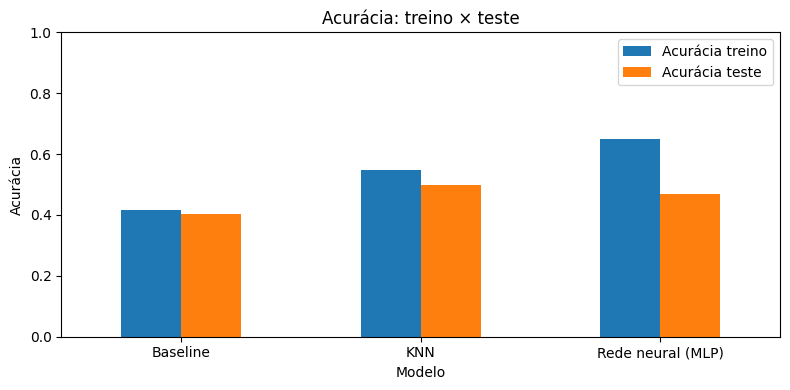

In [5]:
modelos = {'Baseline': baseline, 'KNN': knn, 'Rede neural (MLP)': rede}
linhas = []
for nome, modelo in modelos.items():
    prev_treino = modelo.predict(X_treino)
    prev_teste = modelo.predict(X_teste)
    linhas.append({
        'Modelo': nome,
        'Acurácia treino': accuracy_score(y_treino, prev_treino),
        'Acurácia teste': accuracy_score(y_teste, prev_teste),
        'F1 macro teste': f1_score(y_teste, prev_teste, average='macro', zero_division=0)
    })
comparacao = pd.DataFrame(linhas).set_index('Modelo')
print(comparacao.round(3))

comparacao[['Acurácia treino', 'Acurácia teste']].plot(kind='bar', figsize=(8,4))
plt.title('Acurácia: treino × teste')
plt.ylabel('Acurácia')
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Onde a rede acerta ou erra?

Como o projeto tem três classes, a **acurácia geral** pode esconder problemas com empates. Por isso, também apresentamos o F1 macro e o relatório por classe.

REDE NEURAL
              precision    recall  f1-score   support

     Derrota       0.50      0.58      0.54       243
      Empate       0.22      0.15      0.18       157
     Vitória       0.54      0.55      0.54       270

    accuracy                           0.47       670
   macro avg       0.42      0.43      0.42       670
weighted avg       0.45      0.47      0.46       670

KNN
              precision    recall  f1-score   support

     Derrota       0.51      0.62      0.56       243
      Empate       0.20      0.06      0.09       157
     Vitória       0.54      0.65      0.59       270

    accuracy                           0.50       670
   macro avg       0.41      0.44      0.41       670
weighted avg       0.45      0.50      0.46       670



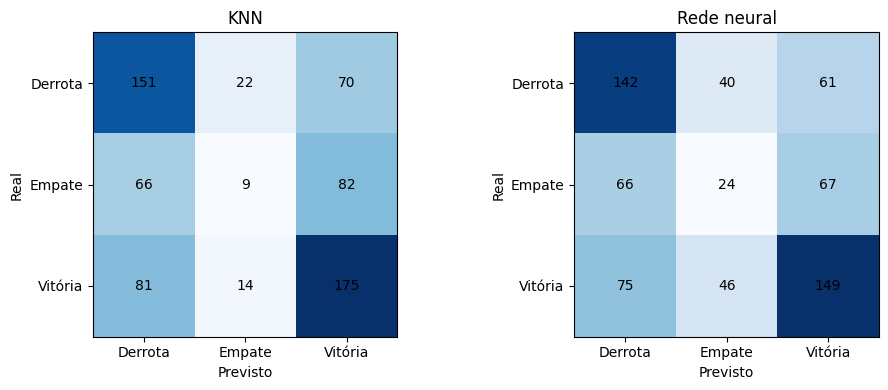

In [6]:
nomes = ['Derrota', 'Empate', 'Vitória']
prev_rede = rede.predict(X_teste)
prev_knn = knn.predict(X_teste)

print('REDE NEURAL')
print(classification_report(y_teste, prev_rede, labels=[0,1,2],
                            target_names=nomes, zero_division=0))
print('KNN')
print(classification_report(y_teste, prev_knn, labels=[0,1,2],
                            target_names=nomes, zero_division=0))

fig, eixos = plt.subplots(1, 2, figsize=(10,4))
for eixo, titulo, previsto in zip(eixos, ['KNN', 'Rede neural'], [prev_knn, prev_rede]):
    matriz = confusion_matrix(y_teste, previsto, labels=[0,1,2])
    eixo.imshow(matriz, cmap='Blues')
    for i in range(3):
        for j in range(3):
            eixo.text(j, i, matriz[i,j], ha='center', va='center')
    eixo.set_xticks(range(3), nomes)
    eixo.set_yticks(range(3), nomes)
    eixo.set_title(titulo)
    eixo.set_xlabel('Previsto')
    eixo.set_ylabel('Real')
plt.tight_layout()
plt.show()

## 7. Diferença treino × teste e diagnóstico

Se a rede for muito melhor no treino do que no teste, isso é indício de **overfitting**. Se os dois resultados forem baixos, pode haver **underfitting** ou falta de informação nas variáveis. A presença de `ConvergenceWarning` indica que o otimizador atingiu o limite de iterações sem satisfazer o critério de convergência; não significa que o código falhou.

In [7]:
ac_treino = comparacao.loc['Rede neural (MLP)', 'Acurácia treino']
ac_teste = comparacao.loc['Rede neural (MLP)', 'Acurácia teste']
print(f'Rede: treino = {ac_treino:.1%}; teste = {ac_teste:.1%}; diferença = {(ac_treino-ac_teste)*100:.1f} pontos percentuais')
print('Loss final da rede:', round(rede.named_steps['modelo'].loss_,4))
print('Épocas executadas:', rede.named_steps['modelo'].n_iter_)
if avisos_convergencia:
    print('Dificuldade técnica: aviso de convergência. Possíveis próximos testes:')
    print('aumentar max_iter, ajustar learning_rate_init ou simplificar a arquitetura.')
else:
    print('Sem aviso de convergência nesta execução.')

Rede: treino = 65.0%; teste = 47.0%; diferença = 18.0 pontos percentuais
Loss final da rede: 0.7858
Épocas executadas: 500
Dificuldade técnica: aviso de convergência. Possíveis próximos testes:
aumentar max_iter, ajustar learning_rate_init ou simplificar a arquitetura.


## 8. Texto para entrega — complete usando os números gerados

**1. Experimento executado:** Foi treinada uma rede `MLPClassifier`, com duas camadas escondidas (32 e 16 neurônios), função de ativação ReLU, otimizador Adam, `max_iter=500` e `random_state=42`. As 11 variáveis de entrada foram padronizadas com `StandardScaler`. A rede executou **[n_iter_]** épocas.

**2. Comparação com o modelo clássico:** O KNN, a rede e o baseline foram treinados e avaliados sobre a mesma divisão cronológica de treino e teste, com as mesmas variáveis. A métrica principal foi a acurácia; também foi analisado o F1 macro. Resultados: baseline **[ ]**, KNN **[ ]** e MLP **[ ]** de acurácia no teste.

**3. Análise:** A rede **[melhorou/piorou/empatou]** em relação ao KNN em **[ ]** pontos percentuais. Uma hipótese técnica é **[ex.: base tabular relativamente pequena, relações difíceis de capturar, desbalanceamento dos empates, arquitetura inadequada]**. O relatório por classe mostrou **[ ]**.

**4. Treino × teste:** A acurácia da rede foi **[ ]** no treino e **[ ]** no teste. A diferença de **[ ]** pontos percentuais **[sugere/não sugere]** overfitting relevante.

**5. Decisão:** **[Usaremos / Não usaremos]** a rede neural no projeto final, porque **[comparação objetiva com KNN, baseline e desempenho nos empates]**.

**6. Dificuldades:** O treinamento **[apresentou/não apresentou]** `ConvergenceWarning`. Foram usados `StandardScaler` e um limite de 500 épocas. **[Se houver aviso, registrar que o limite foi atingido e que a convergência precisa de investigação; não afirmar que foi resolvido sem testar.]**

**Limitação importante:** o resultado depende da arquitetura e dos hiperparâmetros escolhidos. Um único experimento não demonstra que todas as redes neurais são melhores ou piores que o KNN.